# Asymmetry of II

In [1]:
import jax
from jax import numpy as jnp
from jax import random
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import json
import argparse
from matplotlib import cycler  # NEW
import scienceplots
import pickle
from information_imbalance import build_information_imbalance
import cka
from tqdm import tqdm

In [2]:
plt.style.use(['nature', 'science'])

In [3]:
# -----------------------------
# Global config
# -----------------------------
D = 10              # feature dimension
S_DEFAULT = 10      # number of rank steps (from full to rank 1)

In [4]:
def rank_schedule_full_to_one(S: int, dim: int = D) -> jnp.ndarray:
    """
    Monotone decreasing ranks from full (dim) down to 1:
        r_0 = dim, r_{S-1} = 1.
    """
    s = jnp.arange(S)
    ranks = dim - (dim - 1) * (s / (S - 1))
    ranks = jnp.rint(ranks).astype(jnp.int32)

    ranks = ranks.at[0].set(dim)
    ranks = ranks.at[S - 1].set(1)
    return ranks

In [5]:
def noise_schedule_increasing(
    S: int,
    sigma_start: float = 0.02,
    sigma_end: float = 0.2,
) -> jnp.ndarray:
    """
    Noise increases from sigma_start at s=0 to sigma_end at s=S-1.
    """
    s = jnp.arange(S)
    sigmas = sigma_start + (sigma_end - sigma_start) * (s / (S - 1))
    sigmas = sigmas.at[0].set(sigma_start)
    sigmas = sigmas.at[S - 1].set(sigma_end)
    return sigmas

In [6]:
# -----------------------------
# Build B_s with given rank
# -----------------------------
def make_rank_matrix(key, rank: int, dim: int = D) -> jnp.ndarray:
    """
    Construct a dim x dim matrix with (at most) 'rank' via low-rank factors.
    B = U @ V, U in R^{dim x rank}, V in R^{rank x dim}.
    """
    key_u, key_v = random.split(key)
    U = random.normal(key_u, (dim, rank))
    V = random.normal(key_v, (rank, dim))
    return U @ V

In [7]:
def build_B_sequence(
    key,
    S: int = S_DEFAULT,
    dim: int = D,
) -> tuple[jnp.ndarray, jnp.ndarray]:
    """
    Build B_s for s=0,...,S-1 with ranks decreasing from full to 1.
    Returns:
        B: (S, dim, dim)
        ranks: (S,)
    """
    ranks = rank_schedule_full_to_one(S, dim=dim)
    keys = random.split(key, S)

    Bs = []
    for s in range(S):
        r = int(ranks[s])
        k = keys[s]
        Bs.append(make_rank_matrix(k, r, dim=dim))

    B = jnp.stack(Bs, axis=0)
    return B, ranks

In [8]:
# -----------------------------
# Simulate X_s, Y_s
# -----------------------------
def simulate_XY(
    key,
    S: int = S_DEFAULT,
    n_samples: int = 500,
    tau: float = 1.0,
    dim: int = D,
    mu: jnp.ndarray | None = None,
    sigma_start: float = 0.02,
    sigma_end: float = 0.2,
):
    """
    DGP:
      X_s ~ N(mu_s, tau^2 I)
      Y_s = B_s X_s + eps_s
      eps_s ~ N(0, sigma_s^2 I)

    - rank(B_s) decreases from dim to 1 as s increases.
    - sigma_s increases from sigma_start to sigma_end.

    Returns:
      X: (S, N, dim)
      Y: (S, N, dim)
      B: (S, dim, dim)
      mu: (S, dim)
      ranks_B: (S,)
      sigma_s: (S,)
    """
    key_B, key_X, key_eps = random.split(key, 3)

    B, ranks_B = build_B_sequence(key_B, S=S, dim=dim)
    sigma_s = noise_schedule_increasing(S, sigma_start=sigma_start, sigma_end=sigma_end)

    if mu is None:
        mu = jnp.zeros((S, dim))

    # X_s
    X_noise = random.normal(key_X, (S, n_samples, dim))
    X = mu[:, None, :] + tau * X_noise

    # eps_s with step-wise noise
    eps_noise = random.normal(key_eps, (S, n_samples, dim))
    eps = sigma_s[:, None, None] * eps_noise

    # Y_s = B_s X_s + eps_s
    Y = jnp.einsum("sij,snj->sni", B, X) + eps

    return X, Y, B, mu, ranks_B, sigma_s

In [9]:
# -----------------------------
# Information imbalance across ranks
# -----------------------------
def compute_imbalance_over_sequence(
    X_snd: jnp.ndarray,
    Y_snd: jnp.ndarray,
    k: int = 1,
    maxk: int | None = None,
    rng_seed: int = 0,
):
    """
    Compute Δ(X->Y), Δ(Y->X) for each index s.
    X_snd, Y_snd: (S, N, D)
    Returns:
      imbal_X_to_Y: (S,)
      imbal_Y_to_X: (S,)
    """
    S, N, _ = X_snd.shape

    if maxk is None:
        maxk = N - 1

    imb_fn = build_information_imbalance(k=k, maxk=maxk, rng=rng_seed)

    imbal_X_to_Y = np.zeros(S)
    imbal_Y_to_X = np.zeros(S)

    for s in range(S):
        Xs = np.asarray(X_snd[s])
        Ys = np.asarray(Y_snd[s])
        d_xy, d_yx = imb_fn(Xs, Ys)
        imbal_X_to_Y[s] = d_xy
        imbal_Y_to_X[s] = d_yx

    return imbal_X_to_Y, imbal_Y_to_X

In [10]:
def linear_cka(X: np.ndarray, Y: np.ndarray, eps: float = 1e-12) -> float:
    """
    Compute linear CKA between two representations X and Y.

    X, Y: (N, D)
      N = number of samples, D = feature dimension

    CKA is invariant to isotropic scaling and orthogonal transforms,
    and uses the feature-space (linear kernel) formulation:

      CKA(X, Y) = ||Y^T X||_F^2 / ( ||X^T X||_F * ||Y^T Y||_F )
    
    with both X and Y centered per feature.
    """
    # Center features
    Xc = X - X.mean(axis=0, keepdims=True)
    Yc = Y - Y.mean(axis=0, keepdims=True)

    # Cross-covariance in feature space
    XtY = Xc.T @ Yc      # (D, D)
    hsic = np.sum(XtY ** 2)

    # Self-covariance norms
    XtX = Xc.T @ Xc
    YtY = Yc.T @ Yc
    norm_X = np.sqrt(np.sum(XtX ** 2))
    norm_Y = np.sqrt(np.sum(YtY ** 2))

    denom = norm_X * norm_Y + eps
    return float(hsic / denom)

In [11]:
def compute_cka_over_sequence(
    X_snd: jnp.ndarray,
    Y_snd: jnp.ndarray,
) -> np.ndarray:
    """
    Compute linear CKA between X_s and Y_s for each index s.

    X_snd, Y_snd: JAX arrays of shape (S, N, D)
    Returns:
        cka_vals: (S,) numpy array
    """
    S, N, D = X_snd.shape
    cka_vals = np.zeros(S, dtype=np.float64)

    for s in range(S):
        Xs = np.asarray(X_snd[s])  # (N, D)
        Ys = np.asarray(Y_snd[s])  # (N, D)
        cka_vals[s] = linear_cka(Xs, Ys)

    return cka_vals


In [12]:
key = random.PRNGKey(0)
S = 10
n_samples = 2000
tau = 1.
dim = 10
sigma_start = 0.5
sigma_end = 0.5
jack_size = 200
jack_niter = 10

In [13]:
# 1) Simulate DGP
key, subkey = jax.random.split(key)
X_snd, Y_snd, B_sij, mu, ranks_B, sigma_s = simulate_XY(
    subkey,
    S=S,
    n_samples=n_samples,
    tau=tau,
    dim=dim,
    sigma_start=sigma_start,
    sigma_end=sigma_end,
)

In [14]:
X_snd.shape

(10, 2000, 10)

In [15]:
# 2) Compute information imbalance
imbal_XY, imbal_YX = {}, {}
cka_vals = {}

In [16]:
for i in tqdm(range(jack_niter)):
    key, subkey = jax.random.split(key)
    idx = jax.random.choice(key=subkey, a=jnp.arange(n_samples), shape=(jack_size,), replace=False)
    X = X_snd[:, idx, :]
    Y = Y_snd[:, idx, :]
    imbal_XY[str(i)], imbal_YX[str(i)] = compute_imbalance_over_sequence(
    X,
    Y,
    k=1,
    maxk=80,
    rng_seed=0
    )
    cka_vals[str(i)] = compute_cka_over_sequence(X, Y)

100%|████████████████████████████████████████████████████████████████████████████████| 10/10 [00:01<00:00,  5.52it/s]


In [17]:
# 3) Numerical ranks (sanity check; should match ranks_B)
ranks_numerical = np.array(
    [np.linalg.matrix_rank(np.asarray(B_sij[s]), tol=1e-5) for s in range(S)]
)

In [18]:
inf_imb = {}
cka = {}

In [19]:
with open("infimbgauss/ii/gaussian_p_100000_small.pickle", "rb") as f:
    inf_imb["high-p"] = pickle.load(f)

/tmp/ipykernel_985823/3954624853.py:2: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  inf_imb["high-p"] = pickle.load(f)


In [20]:
with open("infimbgauss/ii/gaussian_p_1000_small.pickle", "rb") as f:
    inf_imb["low-p"] = pickle.load(f)

/tmp/ipykernel_985823/2469393688.py:2: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  inf_imb["low-p"] = pickle.load(f)


In [21]:
with open("infimbgauss/cka/gaussian_p_100000_small.pickle", "rb") as f:
    cka["high-p"] = pickle.load(f)

/tmp/ipykernel_985823/794909720.py:2: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  cka["high-p"] = pickle.load(f)


In [22]:
cka["high-p"].keys()

dict_keys(['0', '1', '2', '3', '4', '5', '6', '7', '8', '9'])

In [23]:
with open("infimbgauss/cka/gaussian_p_1000_small.pickle", "rb") as f:
    cka["low-p"] = pickle.load(f)

/tmp/ipykernel_985823/889670279.py:2: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  cka["low-p"] = pickle.load(f)


In [40]:
inf_imb["high-p"][str(i)]["2000"][:10]

array([[0.992095  , 1.0534772 ],
       [0.8551782 , 0.8426735 ],
       [0.7695591 , 0.7969919 ],
       [0.74626327, 0.75012815],
       [0.6641275 , 0.7255753 ],
       [0.6622482 , 0.67905873],
       [0.64865226, 0.67326134],
       [0.6198123 , 0.6614509 ],
       [0.5717292 , 0.62593806],
       [0.5468042 , 0.6055347 ]], dtype=float32)

In [42]:
inf_imb_high_p = np.stack([inf_imb["high-p"][str(i)]["2000"][:, 0] for i in range(jack_niter)])
inf_imb_low_p = np.stack([inf_imb["low-p"][str(i)]["2000"][:, 0]  for i in range(jack_niter)])
cka_high_p = np.stack([cka["high-p"][str(i)]["2000"]  for i in range(jack_niter)])
cka_low_p = np.stack([cka["low-p"][str(i)]["2000"]  for i in range(jack_niter)])

In [43]:
imbal_XY_arr = np.stack([imbal_XY[str(i)] for i in range(jack_niter)])
imbal_YX_arr = np.stack([imbal_YX[str(i)] for i in range(jack_niter)])
cka_arr       = np.stack([cka_vals[str(i)] for i in range(jack_niter)])

In [44]:
mean_imbal_XY = imbal_XY_arr.mean(axis=0)
std_imbal_XY  = imbal_XY_arr.std(axis=0)

mean_imbal_YX = imbal_YX_arr.mean(axis=0)
std_imbal_YX  = imbal_YX_arr.std(axis=0)

mean_cka = cka_arr.mean(axis=0)
std_cka  = cka_arr.std(axis=0)

In [45]:
mean_inf_imb_high_p = inf_imb_high_p.mean(axis=0)
std_inf_imb_high_p = inf_imb_high_p.std(axis=0)

mean_inf_imb_low_p = inf_imb_low_p.mean(axis=0)
std_inf_imb_low_p = inf_imb_low_p.std(axis=0)

mean_cka_high_p = cka_high_p.mean(axis=0)
std_cka_high_p = cka_high_p.std(axis=0)

mean_cka_low_p = cka_low_p.mean(axis=0)
std_cka_low_p = cka_low_p.std(axis=0)

<>:74: SyntaxWarning: invalid escape sequence '\%'
<>:99: SyntaxWarning: invalid escape sequence '\%'
<>:74: SyntaxWarning: invalid escape sequence '\%'
<>:99: SyntaxWarning: invalid escape sequence '\%'
/tmp/ipykernel_985823/1150847749.py:74: SyntaxWarning: invalid escape sequence '\%'
  ax3.set_xlabel("\% of shared components", fontsize=11)
/tmp/ipykernel_985823/1150847749.py:99: SyntaxWarning: invalid escape sequence '\%'
  ax4.set_xlabel("\% of shared components", fontsize=11)


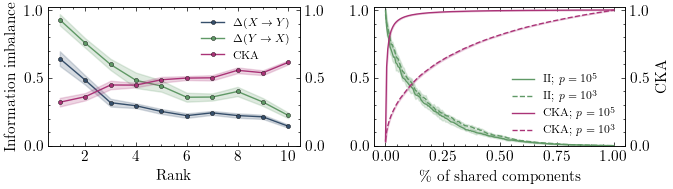

In [58]:
ranks = np.arange(S, 0, -1)  # [S, S-1, ..., 1]
y_lim = 1.02

# --- Create a single figure with 2 subplots (left & right) ---
fig, axes = plt.subplots(1, 2, figsize=(7, 2.0))  # 2 * 3.5 width

# =======================
# LEFT PLOT (Rank plot)
# =======================
ax1 = axes[0]

ax1.plot(ranks, mean_imbal_XY, '-o', color="#364F6B",
         markersize=3, markeredgecolor='black', markeredgewidth=0.3,
         label=r"$\Delta(X \rightarrow Y)$")
ax1.fill_between(ranks,
                mean_imbal_XY - std_imbal_XY,
                mean_imbal_XY + std_imbal_XY,
                alpha=0.2, color="#364F6B")

ax1.plot(ranks, mean_imbal_YX, '-o', color="#609966",
         markersize=3, markeredgecolor='black', markeredgewidth=0.3,
         label=r"$\Delta(Y \rightarrow X)$")
ax1.fill_between(ranks,
                mean_imbal_YX - std_imbal_YX,
                mean_imbal_YX + std_imbal_YX,
                alpha=0.2, color="#609966")

ax1.set_xlabel("Rank", fontsize=11)
ax1.set_ylabel("Information imbalance", fontsize=11)
ax1.set_ylim(0, y_lim)
ax1.tick_params(axis='x', labelsize=11)
ax1.tick_params(axis='y', labelsize=11)

ax2 = ax1.twinx()
ax2.plot(ranks, mean_cka, '-o', color="#AA3377",
         markersize=3, markeredgecolor='black', markeredgewidth=0.3,
         label="CKA")
ax2.fill_between(ranks,
                mean_cka - std_cka,
                mean_cka + std_cka,
                alpha=0.2, color="#AA3377")
# ax2.set_ylabel("CKA", fontsize=11)
ax2.set_ylim(0, y_lim)
ax2.tick_params(axis='y', labelsize=11)

# Legend for left subplot (combine both axes)
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2,
           fontsize=8, loc="best")

# =======================
# RIGHT PLOT (% components)
# =======================
ax3 = axes[1]

x = np.linspace(0, 1, 200)

# Left axis → Information Imbalance
ax3.plot(x, mean_inf_imb_high_p,
         color="#609966", label=r"II; $p = 10^5$")
ax3.fill_between(x,
                mean_inf_imb_high_p - std_inf_imb_high_p,
                mean_inf_imb_high_p + std_inf_imb_high_p,
                alpha=0.2, color="#609966")

ax3.plot(x, mean_inf_imb_low_p,
         color="#609966", linestyle="--", label=r"II; $p = 10^3$")
ax3.fill_between(x,
                mean_inf_imb_low_p - std_inf_imb_low_p,
                mean_inf_imb_low_p + std_inf_imb_low_p,
                alpha=0.2, color="#609966")

ax3.set_xlabel("\% of shared components", fontsize=11)
# ax3.set_ylabel("Information Imbalance", fontsize=11)
ax3.set_ylim(0, y_lim)
ax3.tick_params(axis='x', labelsize=11)
ax3.tick_params(axis='y', labelsize=11)

# Right axis → CKA
ax4 = ax3.twinx()
ax4.plot(x, mean_cka_high_p,
         color="#AA3377", label=r"CKA; $p = 10^5$")
ax4.fill_between(x,
                mean_cka_high_p - std_cka_high_p,
                mean_cka_high_p + std_cka_high_p,
                alpha=0.2, color="#AA3377")

ax4.plot(x, mean_cka_low_p,
         color="#AA3377", linestyle="--", label=r"CKA; $p = 10^3$")
ax4.fill_between(x,
                mean_cka_low_p - std_cka_low_p,
                mean_cka_low_p + std_cka_low_p,
                alpha=0.2, color="#AA3377")

ax4.set_ylabel("CKA", fontsize=11)
ax4.set_ylim(0, y_lim)
ax4.tick_params(axis='y', labelsize=11)
ax4.set_xlabel("\% of shared components", fontsize=11)

# Legend for right subplot (combine both axes)
lines3, labels3 = ax3.get_legend_handles_labels()
lines4, labels4 = ax4.get_legend_handles_labels()
ax3.legend(lines3 + lines4, labels3 + labels4,
           fontsize=8, loc="lower right")

# Layout & save
plt.tight_layout()
plt.savefig("combined_ii_cka.pdf", dpi=300)
# plt.show()
